# 05 · EDA: autenticación de billetes

Objetivo: entender qué variables separan los billetes falsos de los auténticos y qué debe saber el modelo.

In [1]:
import sys
sys.path.append("..")  # para importar src/ desde notebooks/

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.limpieza import cargar_raw, limpiar, FEATURES, TARGET

sns.set_theme(style="whitegrid")
raw = cargar_raw()
df = limpiar(raw)
print("raw:", raw.shape, "| limpio:", df.shape)
df.head()

raw: (1372, 5) | limpio: (1348, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


## 1. Perfil general

In [2]:
print(df.dtypes)
print("Nulos:", int(df.isna().sum().sum()))
df.describe().round(2)

variance    float64
skewness    float64
curtosis    float64
entropy     float64
class         int64
dtype: object
Nulos: 0


,variance,skewness,curtosis,entropy,class
count,1348.00,1348.00,1348.00,1348.00,1348.00
mean,0.45,1.91,1.41,-1.17,0.45
std,2.86,5.87,4.33,2.09,0.50
min,-7.04,-13.77,-5.29,-8.55,0.00
25%,-1.79,-1.63,-1.55,-2.39,0.00
50%,0.52,2.33,0.61,-0.58,0.00
75%,2.85,6.80,3.20,0.40,1.00
max,6.82,12.95,17.93,2.45,1.00


## 2. Balance de clases

class
Auténtico    738
Falso        610
Name: count, dtype: int64
class
Auténtico    0.547
Falso        0.453
Name: count, dtype: float64


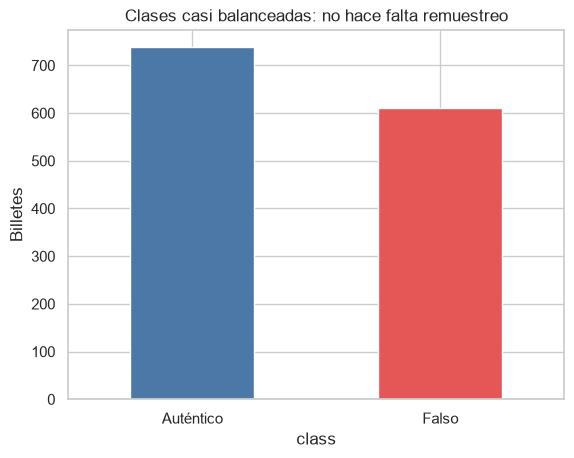

In [3]:
conteo = df[TARGET].value_counts().rename({0: "Auténtico", 1: "Falso"})
print(conteo)
print((conteo / len(df)).round(3))
ax = conteo.plot.bar(color=["#4C78A8", "#E45756"], rot=0)
ax.set_title("Clases casi balanceadas: no hace falta remuestreo")
ax.set_ylabel("Billetes")
plt.show()

## 3. Hallazgo 1: `variance` es la variable que mejor separa las clases

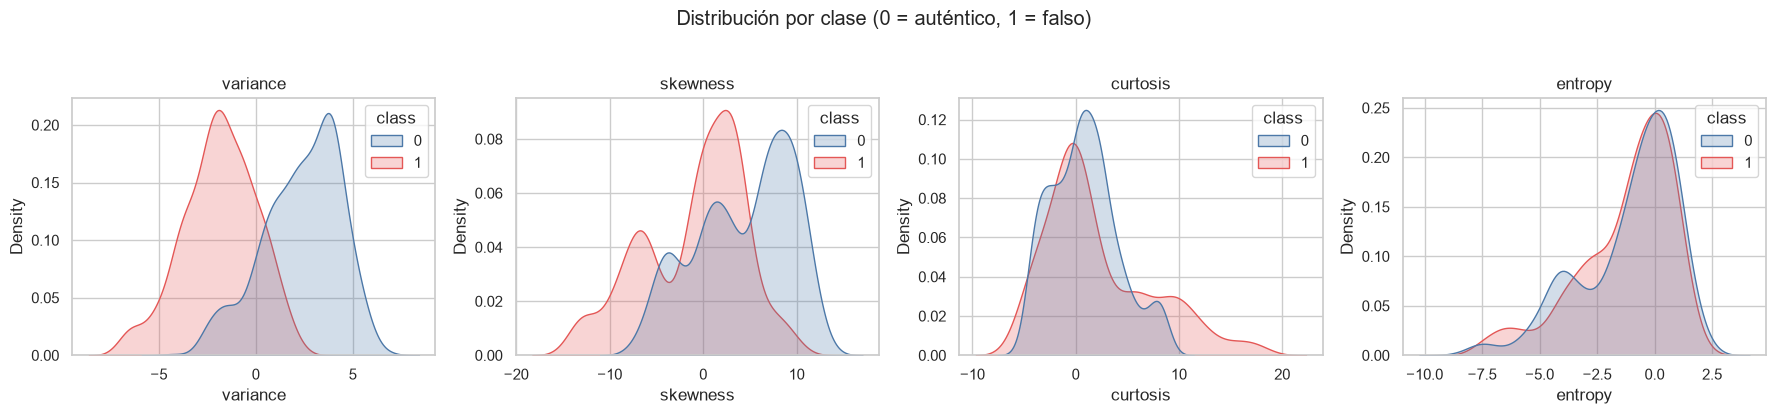

       variance  skewness  curtosis  entropy
class                                       
0          2.36      4.31      0.81    -1.10
1         -1.87     -0.99      2.15    -1.25


In [4]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, FEATURES):
    sns.kdeplot(data=df, x=col, hue=TARGET, fill=True, common_norm=False, ax=ax, palette=["#4C78A8", "#E45756"])
    ax.set_title(col)
plt.suptitle("Distribución por clase (0 = auténtico, 1 = falso)", y=1.03)
plt.tight_layout()
plt.show()
print(df.groupby(TARGET)[FEATURES].mean().round(2))

## 4. Hallazgo 2: `entropy` casi no aporta; `variance` y `skewness` son las más útiles

variance   -0.735
skewness   -0.450
curtosis    0.154
entropy    -0.034
Name: class, dtype: float64


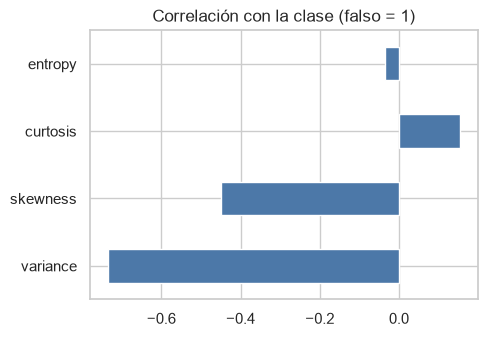

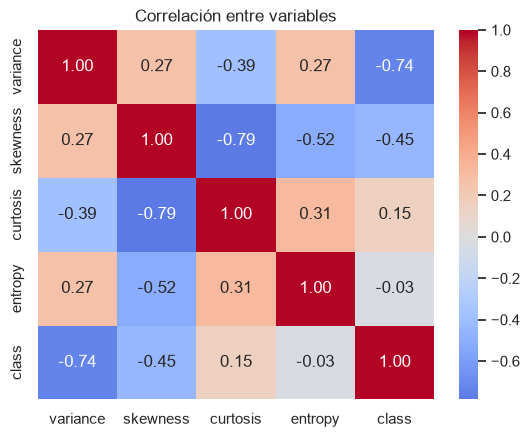

In [5]:
corr = df.corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
print(corr.round(3))
fig, ax = plt.subplots(figsize=(5, 3.5))
corr.plot.barh(ax=ax, color="#4C78A8")
ax.set_title("Correlación con la clase (falso = 1)")
plt.show()
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlación entre variables")
plt.show()

## 5. Hallazgo 3: combinando `variance` y `skewness` las clases casi se separan a simple vista

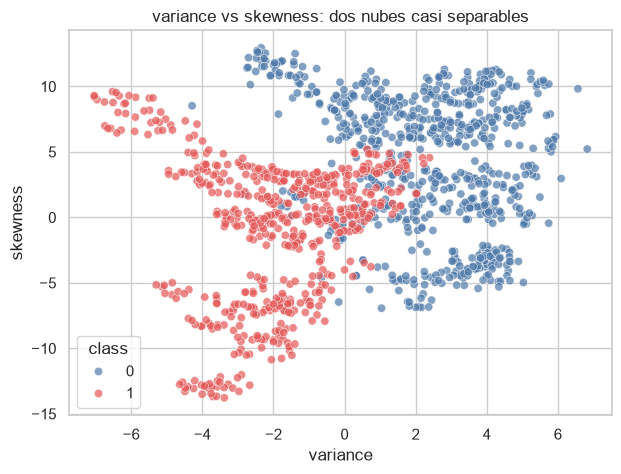

In [6]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="variance", y="skewness", hue=TARGET, palette=["#4C78A8", "#E45756"], alpha=0.7)
plt.title("variance vs skewness: dos nubes casi separables")
plt.show()

## 6. Valores atípicos

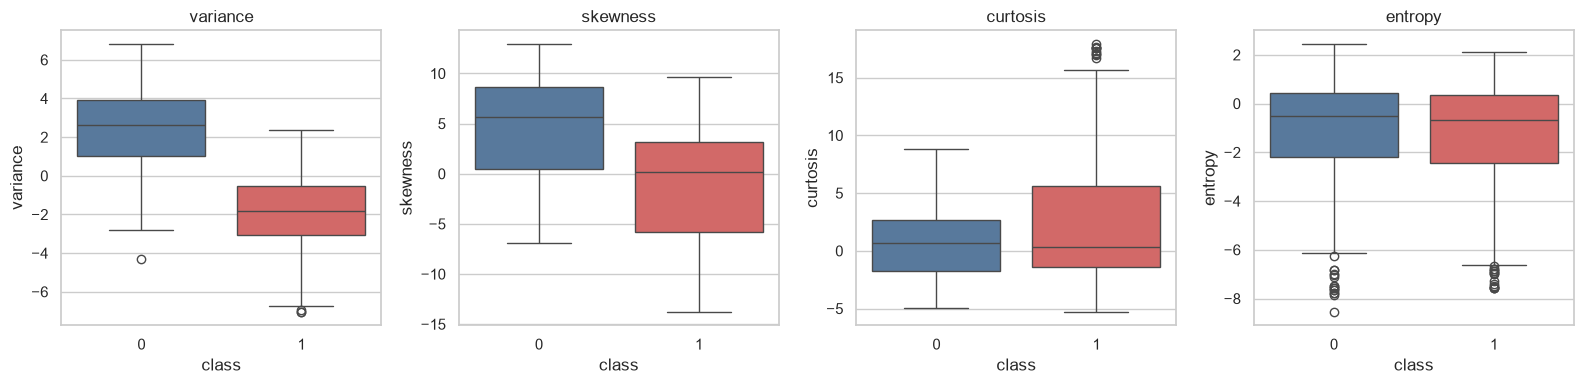

Atípicos por regla 1.5·IQR:
variance     0
skewness     0
curtosis    59
entropy     32
dtype: int64


In [7]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, FEATURES):
    sns.boxplot(data=df, x=TARGET, y=col, ax=ax, palette=["#4C78A8", "#E45756"], hue=TARGET, legend=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()
q1, q3 = df[FEATURES].quantile(0.25), df[FEATURES].quantile(0.75)
iqr = q3 - q1
atipicos = ((df[FEATURES] < q1 - 1.5 * iqr) | (df[FEATURES] > q3 + 1.5 * iqr)).sum()
print("Atípicos por regla 1.5·IQR:")
print(atipicos)

## Conclusiones

1. `variance` separa mejor las clases: los billetes falsos tienen varianza baja o negativa y los auténticos, positiva.
2. `entropy` casi no se relaciona con la clase; `skewness` ayuda a separar. `curtosis` aporta poco por sí sola.
3. Con solo `variance` y `skewness` las clases forman nubes casi separables, así que se espera un modelo con rendimiento muy alto. Hay que protegerse del *data leakage* y no sorprenderse por métricas cercanas a 1.
4. Los valores atípicos son mediciones reales y no se eliminan.